<div style="background:linear-gradient(120deg,#1B2A49 0%,#1B2A49 55%,#C8102E 100%);color:#ffffff;padding:34px 30px;border-radius:14px;font-family:Segoe UI,Arial,sans-serif">
<div style="font-size:30px;font-weight:700;margin:10px 0 6px 0">💳 Credit Card Fraud Detection</div>
<div style="font-size:18px;opacity:.95">Imbalanced Classification with Threshold Optimisation</div>


### 🗺️ Roadmap
| # | Step | What happens |
|---|------|--------------|
| 1 | Problem framing | Theory notes on imbalance, PR trade-off, costs |
| 2 | Loading & EDA | 50k stratified sample, fraud vs legit patterns |
| 3 | Preprocessing | Feature engineering, scaling, split, SMOTE / undersampling |
| 4 | Logistic Regression & Random Forest | Three imbalance strategies compared |
| 5 | XGBoost | Baseline, randomized search, threshold optimisation |
| 6 | Evaluation | All models and thresholds in one table + PR curves |
| 7 | Business simulation | Rupee cost-benefit and threshold sensitivity |
| 8 | Pipeline & submission | Saved `.pkl`, README, summary report |

In [1]:
import warnings, json, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display, Markdown
from matplotlib.colors import LinearSegmentedColormap

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score)
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

# ---- visual identity: Red & White theme -------------------------------------------------
RED, NAVY, GREY, TEAL, AMBER = "#C8102E", "#1B2A49", "#8A94A6", "#2A9D8F", "#E9A23B"
CLASS_COLORS = {0: NAVY, 1: RED}
DIVERGING = LinearSegmentedColormap.from_list("rw", [NAVY, "#FFFFFF", RED])

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#C9CED8", "axes.labelcolor": NAVY, "axes.titlecolor": NAVY,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#ECEEF2",
    "grid.linewidth": 0.8, "xtick.color": NAVY, "ytick.color": NAVY,
    "legend.frameon": False, "font.size": 10.5,
})
sns.set_palette([NAVY, RED, TEAL, AMBER, GREY])

pd.options.display.float_format = "{:,.4f}".format
print("Libraries ready.")

Libraries ready.


<div style="background:linear-gradient(90deg,#C8102E,#8E0B21);color:#ffffff;padding:14px 22px;border-radius:10px;font-family:Segoe UI,Arial,sans-serif;font-size:21px;font-weight:600;margin:18px 0 6px 0">🧠&nbsp; Step 1 · Problem Framing &amp; Theory Notes<div style="font-size:13px;font-weight:400;opacity:.9;margin-top:2px">Business reasoning first, code second</div></div>

#### Q1 · Why is accuracy a terrible metric for fraud detection?
If 99.83 % of transactions are legitimate and a model predicts **everything as "Not Fraud"**, its accuracy is **99.83 %**. It looks excellent, yet it never catches a single fraud.

* **Precision (Fraud)** = TP / (TP + FP) = 0 / 0, which is undefined and reported as **0** because the model never flags anything.
* **Recall (Fraud)** = TP / (TP + FN) = 0 / (all frauds) = **0 %**, so every fraud slips through.

Accuracy rewards the model for the easy majority class, so it hides total failure on the class that costs money.

#### Q2 · What is the Precision-Recall trade-off?
Precision answers *"of the transactions I flagged, how many were truly fraud?"* and Recall answers *"of all the frauds, how many did I catch?"*.

|  | **Predicted Fraud** | **Predicted Legit** |
|---|---|---|
| **Actually Fraud** | TP: fraud caught | FN: fraud missed (costly) |
| **Actually Legit** | FP: false alarm | TN: correctly passed |

When the threshold is lowered from 0.5 to 0.2, the model flags a transaction as fraud on weaker evidence. **Recall rises** (fewer FN) but **Precision falls** (more FP), because many more legitimate transactions get flagged. One metric can only be improved at the expense of the other, which is why the threshold is a business choice.

#### Q3 · Three strategies for extreme class imbalance
| Strategy | How it works | Pros | Cons |
|---|---|---|---|
| **(a) Random undersampling** | Randomly drop majority-class rows until the classes are closer in size | Fast to train; simple; pushes the model to focus on fraud | Throws away real information; can raise variance and over-flag fraud |
| **(b) SMOTE oversampling** | Create synthetic fraud points by interpolating between a fraud case and its nearest fraud neighbours | Keeps all data; gives the model more fraud examples to learn from | Synthetic points may be unrealistic or overlap with legit data; slower; must be applied to training data only |
| **(c) `class_weight='balanced'`** | Make each fraud mistake count much more in the loss function | No change to the data; no leakage risk; no extra rows | Does not add new information; may not help models that ignore weights; can hurt calibration |

#### Q4 · What is PR-AUC and why prefer it over ROC-AUC?
**PR-AUC** (average precision) is the area under the Precision-Recall curve, summarising performance across every threshold while focusing only on the positive (fraud) class. **ROC-AUC** includes the huge pool of true negatives in the false-positive rate, so with 0.17 % fraud even thousands of false alarms barely move the FPR and the score stays near 1.0. PR-AUC is not diluted by true negatives, so it exposes weak precision honestly. Its random-guess baseline equals the fraud rate (about 0.0017), not 0.5.

#### Q5 · False Positive or False Negative: which is costlier?
Usually the **False Negative**. A missed fraud of about ₹4,500 is lost money, plus chargebacks and customer trust. A false positive means a wrongly flagged legitimate payment, which costs an analyst around ₹150 of review time and some customer irritation. Example: blocking a genuine ₹800 grocery purchase annoys one customer, whereas letting a stolen-card ₹45,000 transfer through can cost the company the full amount. Because ~30 false alarms cost about the same as one missed fraud, the business-optimal threshold is typically lower than 0.5, and Step 7 quantifies it.

<div style="background:#FFF6E0;border-left:5px solid #E9A23B;color:#1B2A49;padding:10px 16px;border-radius:6px;font-family:Segoe UI,Arial,sans-serif;font-size:14px;margin:6px 0">💡&nbsp; <b>Tip:</b> this exam is as much about business reasoning as coding. Accuracy is never used to pick a model here; PR-AUC, Precision, Recall, F1 and rupee impact are.</div>

<div style="background:linear-gradient(90deg,#C8102E,#8E0B21);color:#ffffff;padding:14px 22px;border-radius:10px;font-family:Segoe UI,Arial,sans-serif;font-size:21px;font-weight:600;margin:18px 0 6px 0">📂&nbsp; Step 2 · Dataset Loading &amp; EDA</div>

<h3 style="color:#1B2A49;font-family:Segoe UI,Arial,sans-serif;border-bottom:2px solid #C8102E;padding-bottom:4px;margin-top:22px">2.1 &nbsp;Load &amp; Sample</h3>

<div style="background:#EEF6F1;border-left:5px solid #2A9D8F;color:#1B2A49;padding:10px 16px;border-radius:6px;font-family:Segoe UI,Arial,sans-serif;font-size:14px;margin:6px 0">📝&nbsp; <b>Data note:</b> place the Kaggle file <code>creditcard.csv</code> next to this notebook (<a href='https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud'>download</a>). If it is missing, the notebook falls back to a <b>synthetic stand-in with the same schema</b> so every cell can still run. Re-run with the real file for your submission.</div>

In [2]:
DATA_PATH = Path("creditcard.csv")


def make_demo_data(n=200_000, fraud_rate=0.00172, seed=7):
    """Synthetic stand-in with the same schema as the Kaggle file (Time, V1-V28, Amount, Class)."""
    rng = np.random.default_rng(seed)
    y = (rng.random(n) < fraud_rate).astype(int)
    f = y == 1
    V = rng.normal(size=(n, 28)) * np.linspace(2.0, 0.5, 28)
    shifts = {3: 2.2, 9: -2.6, 10: 1.8, 11: -2.8, 13: -3.4, 16: -3.0, 1: -1.6, 2: -2.0, 6: -1.4}
    for j, s in shifts.items():
        V[f, j] += s * rng.uniform(0.5, 1.2, f.sum())
    day_w = np.array([2, 1, 1, 1, 1, 2, 4, 6, 8, 9, 9, 9, 9, 9, 9, 9, 9, 9, 8, 8, 7, 6, 4, 3], float)
    fr_w = np.array([9, 9, 10, 9, 8, 6, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 4, 6, 8], float)
    hours = np.where(f, rng.choice(24, n, p=fr_w / fr_w.sum()), rng.choice(24, n, p=day_w / day_w.sum()))
    time = rng.integers(0, 2, n) * 86400 + hours * 3600 + rng.uniform(0, 3600, n)
    amount = np.where(f, rng.lognormal(3.0, 1.8, n), rng.lognormal(3.5, 1.4, n)).round(2)
    df = pd.DataFrame(V, columns=[f"V{i}" for i in range(1, 29)])
    df.insert(0, "Time", time.round(0))
    df["Amount"], df["Class"] = amount, y
    return df.sort_values("Time").reset_index(drop=True)


if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
    USING_DEMO = False
    print("Loaded the real Kaggle dataset.")
else:
    df = make_demo_data()
    USING_DEMO = True
    print("creditcard.csv not found -> using SYNTHETIC DEMO DATA (same schema). Re-run with the real file for submission.")

print("Shape:", df.shape)
print("\nClass distribution (normalised):")
print(df["Class"].value_counts(normalize=True).round(5).to_string())

creditcard.csv not found -> using SYNTHETIC DEMO DATA (same schema). Re-run with the real file for submission.
Shape: (200000, 31)

Class distribution (normalised):
Class
0   0.9984
1   0.0016


In [3]:
# Stratified 50,000-row sample (only the first split is used; the held-out part is discarded)
_, df_s = train_test_split(df, test_size=50_000, stratify=df["Class"], random_state=SEED)
df_s = df_s.reset_index(drop=True)

print("Sample shape:", df_s.shape)
print("Fraud rows in sample:", int(df_s["Class"].sum()))
print("Fraud ratio  full: {:.5f} | sample: {:.5f}  -> stratification preserved".format(
    df["Class"].mean(), df_s["Class"].mean()))
display(df_s[["Time", "Amount"]].describe().T.style.format("{:,.2f}").background_gradient(cmap="Reds", axis=None))

Sample shape: (50000, 31)
Fraud rows in sample: 78
Fraud ratio  full: 0.00157 | sample: 0.00156  -> stratification preserved


,count,mean,std,min,25%,50%,75%,max
Time,"50,000.00","93,224.09","47,186.50",7.00,"50,520.50","86,165.50","136,748.25","172,793.00"
Amount,"50,000.00",89.10,213.32,0.05,12.81,33.03,85.23,"8,175.92"


<h3 style="color:#1B2A49;font-family:Segoe UI,Arial,sans-serif;border-bottom:2px solid #C8102E;padding-bottom:4px;margin-top:22px">2.2 &nbsp;Target &amp; Feature Analysis</h3>

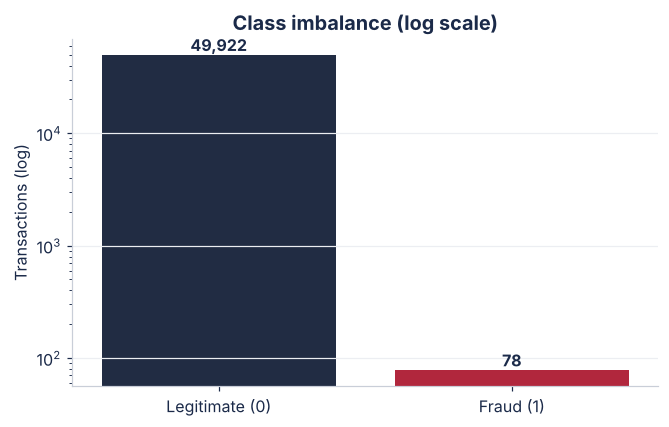

In [4]:
fig, ax = plt.subplots(figsize=(6.2, 4))
sns.countplot(data=df_s, x="Class", hue="Class", palette=CLASS_COLORS, legend=False, ax=ax)
ax.set_yscale("log")
ax.set_xticklabels(["Legitimate (0)", "Fraud (1)"])
ax.set_title("Class imbalance (log scale)")
ax.set_xlabel(""); ax.set_ylabel("Transactions (log)")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontweight="bold", color=NAVY)
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

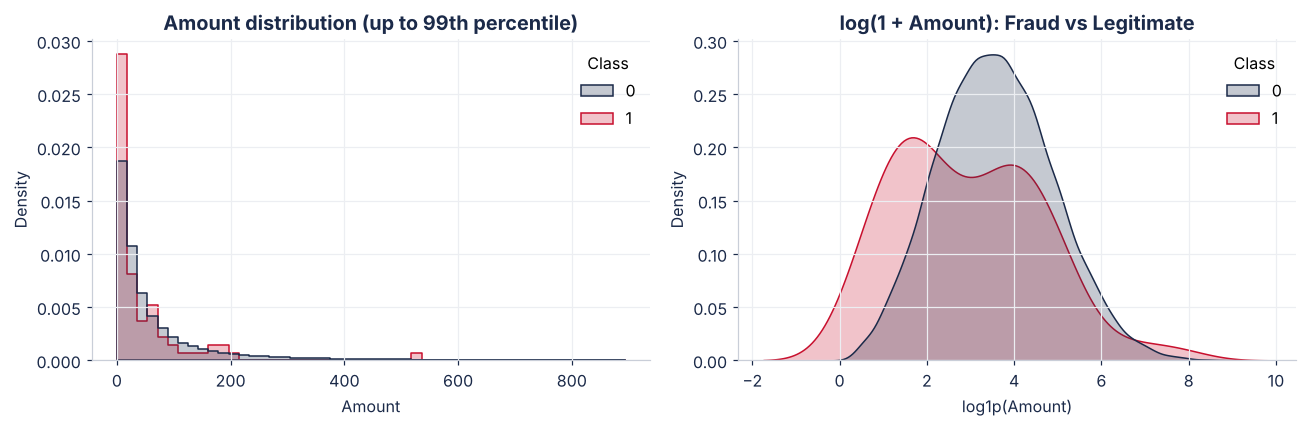

,mean,median,max
Class,,,
Legit,89.10,33.05,"8,175.92"
Fraud,89.01,15.80,"2,436.37"


In [5]:
q99 = df_s["Amount"].quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df_s[df_s["Amount"] <= q99], x="Amount", hue="Class", palette=CLASS_COLORS, stat="density",
             common_norm=False, element="step", bins=50, ax=axes[0])
axes[0].set_title("Amount distribution (up to 99th percentile)")
sns.kdeplot(data=df_s.assign(AmountLog=np.log1p(df_s["Amount"])), x="AmountLog", hue="Class", palette=CLASS_COLORS,
            common_norm=False, fill=True, alpha=.25, ax=axes[1])
axes[1].set_title("log(1 + Amount): Fraud vs Legitimate"); axes[1].set_xlabel("log1p(Amount)")
plt.tight_layout(); plt.show()

amt = df_s.groupby("Class")["Amount"].agg(["mean", "median", "max"]).rename(index={0: "Legit", 1: "Fraud"})
display(amt.style.format("{:,.2f}"))

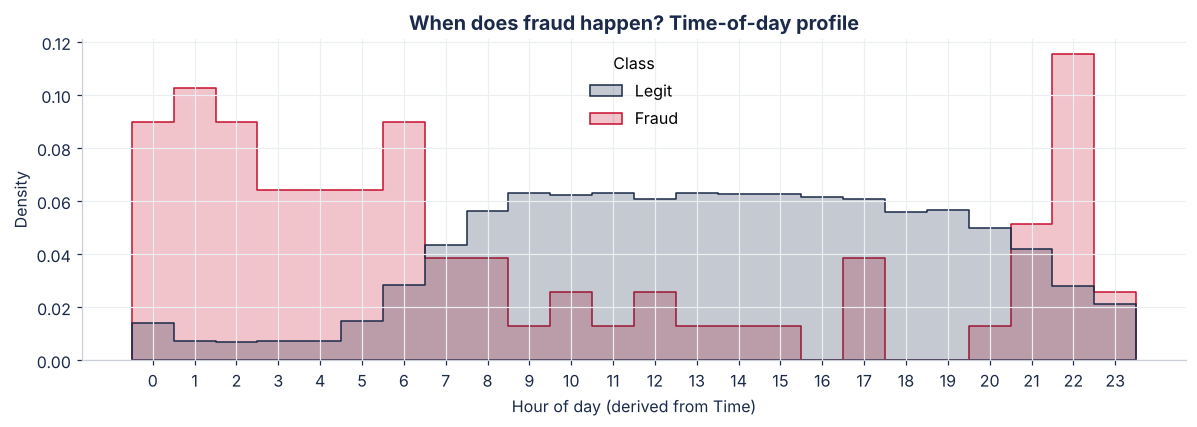

Top-3 fraud hours (share of all fraud): {22: '11.5%', 1: '10.3%', 6: '9.0%'}


In [6]:
hour_eda = ((df_s["Time"] % 86400) // 3600).astype(int)
fig, ax = plt.subplots(figsize=(11, 4))
sns.histplot(x=hour_eda, hue=df_s["Class"].map({0: "Legit", 1: "Fraud"}), palette={"Legit": NAVY, "Fraud": RED},
             stat="density", common_norm=False, discrete=True, element="step", ax=ax)
ax.set_xticks(range(0, 24)); ax.set_xlabel("Hour of day (derived from Time)")
ax.set_title("When does fraud happen? Time-of-day profile")
plt.tight_layout(); plt.show()

fraud_hours = hour_eda[df_s["Class"] == 1].value_counts(normalize=True).head(3)
print("Top-3 fraud hours (share of all fraud):", {int(h): f"{v:.1%}" for h, v in fraud_hours.items()})

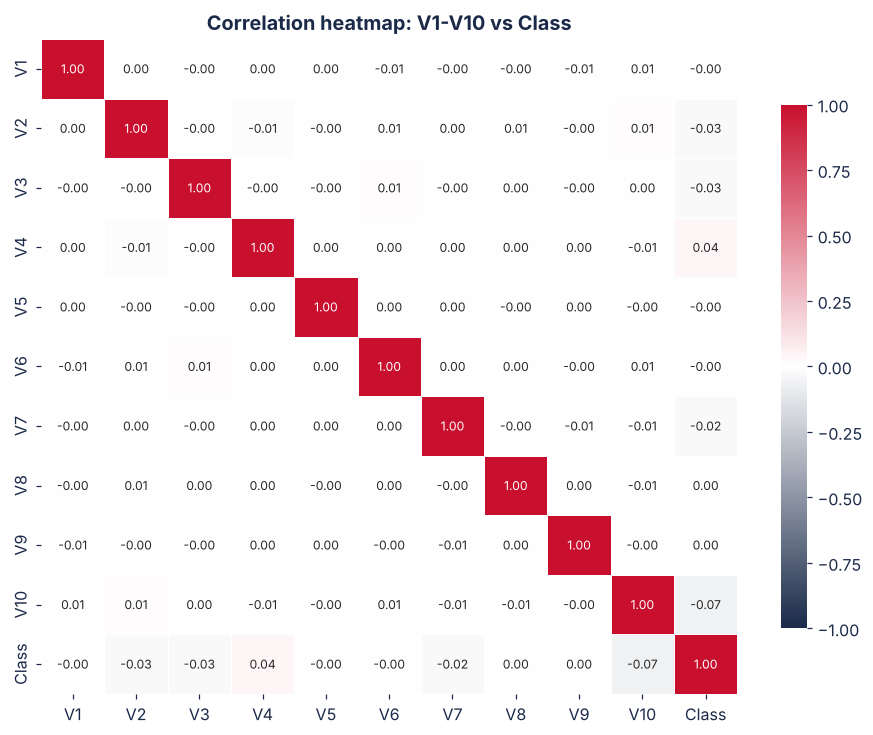

V-features most correlated with fraud (|r|):
V10   -0.0670
V4     0.0420
V2    -0.0310
V3    -0.0260


In [7]:
cols = [f"V{i}" for i in range(1, 11)] + ["Class"]
corr = df_s[cols].corr()
fig, ax = plt.subplots(figsize=(8.5, 6.8))
sns.heatmap(corr, cmap=DIVERGING, center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8},
            linewidths=.5, linecolor="white", cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Correlation heatmap: V1-V10 vs Class"); ax.grid(False)
plt.tight_layout(); plt.show()

top_corr = corr["Class"].drop("Class").abs().sort_values(ascending=False).head(4)
print("V-features most correlated with fraud (|r|):")
print(corr.loc[top_corr.index, "Class"].round(3).to_string())

In [8]:
med_f, med_l = amt.loc["Fraud", "median"], amt.loc["Legit", "median"]
night_share = hour_eda[df_s["Class"] == 1].isin([0, 1, 2, 3, 4, 5]).mean()
night_share_legit = hour_eda[df_s["Class"] == 0].isin([0, 1, 2, 3, 4, 5]).mean()
display(Markdown(f"""**EDA verdict on the key insight**

* **Amount:** median fraud = ₹{med_f:,.2f} vs legit = ₹{med_l:,.2f} -> fraud amounts are **{'smaller' if med_f < med_l else 'not smaller'}** in the middle of the distribution; fraud also shows a heavier spread at the extremes, so the claim holds for typical values, not for every case.
* **Time:** {night_share:.0%} of fraud happens between 00:00-05:59 compared to {night_share_legit:.0%} of legitimate traffic -> fraud **{'does cluster in specific windows' if night_share > night_share_legit + .05 else 'shows no strong time cluster'}**.
* **Features:** the V-features listed above carry the strongest linear signal; a tree model can also use non-linear structure."""))

**EDA verdict on the key insight**

* **Amount:** median fraud = ₹15.80 vs legit = ₹33.05 -> fraud amounts are **smaller** in the middle of the distribution; fraud also shows a heavier spread at the extremes, so the claim holds for typical values, not for every case.
* **Time:** 47% of fraud happens between 00:00-05:59 compared to 6% of legitimate traffic -> fraud **does cluster in specific windows**.
* **Features:** the V-features listed above carry the strongest linear signal; a tree model can also use non-linear structure.

<div style="background:#E8F1F8;border-left:5px solid #2F6690;color:#1B2A49;padding:10px 16px;border-radius:6px;font-family:Segoe UI,Arial,sans-serif;font-size:14px;margin:6px 0">📌&nbsp; <b>Key insight to check:</b> fraud tends to have smaller amounts and cluster in specific time windows. The verdict above is computed from your data, so it will reflect the real file when you re-run.</div>

<div style="background:linear-gradient(90deg,#C8102E,#8E0B21);color:#ffffff;padding:14px 22px;border-radius:10px;font-family:Segoe UI,Arial,sans-serif;font-size:21px;font-weight:600;margin:18px 0 6px 0">🔧&nbsp; Step 3 · Data Preprocessing &amp; Feature Engineering</div>

<h3 style="color:#1B2A49;font-family:Segoe UI,Arial,sans-serif;border-bottom:2px solid #C8102E;padding-bottom:4px;margin-top:22px">3.1 &nbsp;Feature Engineering</h3>

In [9]:
data = df_s.copy()
data["Amount_log"] = np.log1p(data["Amount"])            # tame the right-skewed Amount
data["Hour"] = (data["Time"] % 86400) // 3600            # hour of day from seconds since first transaction
data = data.drop(columns=["Time", "Amount"])             # drop originals

feature_cols = [f"V{i}" for i in range(1, 29)] + ["Amount_log", "Hour"]
X_all, y_all = data[feature_cols], data["Class"]
print("Features:", len(feature_cols), "->", feature_cols[-4:], "...")
display(data[["Amount_log", "Hour", "Class"]].head())

Features: 30 -> ['V27', 'V28', 'Amount_log', 'Hour'] ...


,Amount_log,Hour,Class
0,1.1569,12.0000,0
1,2.5802,8.0000,0
2,2.4689,20.0000,0
3,2.1576,23.0000,0
4,6.2728,14.0000,0


<h3 style="color:#1B2A49;font-family:Segoe UI,Arial,sans-serif;border-bottom:2px solid #C8102E;padding-bottom:4px;margin-top:22px">3.2 &amp; 3.3 &nbsp;Train-Test Split and Scaling</h3>

<div style="background:#EEF6F1;border-left:5px solid #2A9D8F;color:#1B2A49;padding:10px 16px;border-radius:6px;font-family:Segoe UI,Arial,sans-serif;font-size:14px;margin:6px 0">📝&nbsp; The split is performed <b>before</b> scaling so the scaler is fitted on training data only. This prevents the test set from leaking into the preprocessing. Only <code>Amount_log</code> and <code>Hour</code> are scaled because V1-V28 are already PCA-scaled.</div>

In [10]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED)

print(f"{'Set':<7}{'Rows':>8}{'Fraud':>8}{'Fraud %':>10}")
for name, yy in [("Train", y_train), ("Test", y_test)]:
    print(f"{name:<7}{len(yy):>8,}{int(yy.sum()):>8}{yy.mean():>10.3%}")
print(f"Full sample fraud ratio: {y_all.mean():.3%} -> stratification preserved the fraud ratio")

scaler = ColumnTransformer([("scale", StandardScaler(), ["Amount_log", "Hour"])],
                           remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")
X_train = scaler.fit_transform(X_train_raw)      # scaled columns first, V-features passed through
X_test = scaler.transform(X_test_raw)
model_cols = list(X_train.columns)               # the exact column order every model is trained on

# fingerprint of the test set - checked again at the very end to prove it was never modified
TEST_FINGERPRINT = (int(pd.util.hash_pandas_object(X_test).sum()), int(pd.util.hash_pandas_object(y_test).sum()))
display(X_train[["Amount_log", "Hour"]].describe().loc[["mean", "std"]].style.format("{:.3f}"))

Set        Rows   Fraud   Fraud %
Train    40,000      62    0.155%
Test     10,000      16    0.160%
Full sample fraud ratio: 0.156% -> stratification preserved the fraud ratio


,Amount_log,Hour
mean,0.000,-0.000
std,1.000,1.000


In [11]:
# Why accuracy lies: a "predict everything legitimate" baseline on the real test set
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
d_pred = dummy.predict(X_test)
dummy_acc = float((d_pred == y_test).mean())
dummy_prec = float(precision_score(y_test, d_pred, zero_division=0))
dummy_rec = float(recall_score(y_test, d_pred, zero_division=0))
print(f"Always-'Not Fraud' baseline  ->  Accuracy {dummy_acc:.2%} | Precision {dummy_prec:.2f} | Recall {dummy_rec:.2f}")

Always-'Not Fraud' baseline  ->  Accuracy 99.84% | Precision 0.00 | Recall 0.00


<h3 style="color:#1B2A49;font-family:Segoe UI,Arial,sans-serif;border-bottom:2px solid #C8102E;padding-bottom:4px;margin-top:22px">3.4 &nbsp;Imbalance Handling: Three Strategies</h3>

In [12]:
X_smote, y_smote = SMOTE(sampling_strategy=0.1, random_state=SEED).fit_resample(X_train, y_train)
X_under, y_under = RandomUnderSampler(sampling_strategy=0.1, random_state=SEED).fit_resample(X_train, y_train)

rows = []
for name, yy in [("Original (imbalanced)", y_train), ("SMOTE (fraud = 10% of legit)", y_smote),
                 ("Undersampled (fraud = 10% of legit)", y_under)]:
    c = pd.Series(yy).value_counts().sort_index()
    rows.append({"Training set": name, "Legit (0)": int(c[0]), "Fraud (1)": int(c[1]), "Fraud ratio": c[1] / c.sum()})
display(pd.DataFrame(rows).style.format({"Legit (0)": "{:,}", "Fraud (1)": "{:,}", "Fraud ratio": "{:.2%}"}).hide(axis="index"))

Training set,Legit (0),Fraud (1),Fraud ratio
Original (imbalanced),"39,938",62,0.15%
SMOTE (fraud = 10% of legit),"39,938","3,993",9.09%
Undersampled (fraud = 10% of legit),620,62,9.09%


<div style="background:#FDECEE;border-left:5px solid #C8102E;color:#1B2A49;padding:10px 16px;border-radius:6px;font-family:Segoe UI,Arial,sans-serif;font-size:14px;margin:6px 0">⚠️&nbsp; <b>Critical rule:</b> <code>X_test, y_test</code> stay untouched. All three strategies are applied to <b>training data only</b>. A fingerprint check at the end of the notebook proves this.</div>

<div style="background:linear-gradient(90deg,#C8102E,#8E0B21);color:#ffffff;padding:14px 22px;border-radius:10px;font-family:Segoe UI,Arial,sans-serif;font-size:21px;font-weight:600;margin:18px 0 6px 0">🌲&nbsp; Step 4 · Model Building: Logistic Regression &amp; Random Forest</div>

In [13]:
def evaluate(name, y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {"Model": name,
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0),
            "F1": f1_score(y_true, pred, zero_division=0),
            "PR-AUC": average_precision_score(y_true, proba),
            "Threshold": threshold}


def pretty(df, best_cols=("Precision", "Recall", "F1", "PR-AUC")):
    fmt = {c: "{:.4f}" for c in df.select_dtypes("number").columns}
    fmt["Threshold"] = "{:.4f}"
    return (df.style.format(fmt).highlight_max(subset=list(best_cols), color="#F8C9D1")
            .set_table_styles([{"selector": "th", "props": [("background-color", RED), ("color", "white")]}])
            .hide(axis="index"))

<h3 style="color:#1B2A49;font-family:Segoe UI,Arial,sans-serif;border-bottom:2px solid #C8102E;padding-bottom:4px;margin-top:22px">4.1 &nbsp;Logistic Regression: Three Variants</h3>

In [14]:
datasets = {"Original": (X_train, y_train), "SMOTE": (X_smote, y_smote), "Undersampled": (X_under, y_under)}
lr_weights = {"Original": "balanced", "SMOTE": None, "Undersampled": None}

lr_models, lr_proba, lr_rows = {}, {}, []
for key, (Xa, ya) in datasets.items():
    m = LogisticRegression(class_weight=lr_weights[key], max_iter=1000, random_state=SEED).fit(Xa, ya)
    p = m.predict_proba(X_test)[:, 1]
    lr_models[key], lr_proba[key] = m, p
    lr_rows.append(evaluate(f"LR | {key}", y_test, p))

lr_df = pd.DataFrame(lr_rows)
display(pretty(lr_df))

best_lr_key = lr_df.loc[lr_df["PR-AUC"].idxmax(), "Model"].split("| ")[1]
print(f"\nBest imbalance strategy for Logistic Regression (by PR-AUC): {best_lr_key}")

Model,Precision,Recall,F1,PR-AUC,Threshold
LR | Original,0.2000,0.9375,0.3297,0.8350,0.5000
LR | SMOTE,0.3889,0.8750,0.5385,0.8621,0.5000
LR | Undersampled,0.2500,0.9375,0.3947,0.8068,0.5000



Best imbalance strategy for Logistic Regression (by PR-AUC): SMOTE


<h3 style="color:#1B2A49;font-family:Segoe UI,Arial,sans-serif;border-bottom:2px solid #C8102E;padding-bottom:4px;margin-top:22px">4.2 &nbsp;Random Forest on the Best Imbalance Strategy</h3>

In [15]:
Xb, yb = datasets[best_lr_key]
rf = RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=SEED, n_jobs=-1).fit(Xb, yb)
rf_proba = rf.predict_proba(X_test)[:, 1]
rf_row = evaluate("Random Forest", y_test, rf_proba)
display(pretty(pd.DataFrame([rf_row])))
print(f"(trained on the '{best_lr_key}' training set)")

Model,Precision,Recall,F1,PR-AUC,Threshold
Random Forest,0.4000,0.1250,0.1905,0.3813,0.5000


(trained on the 'SMOTE' training set)


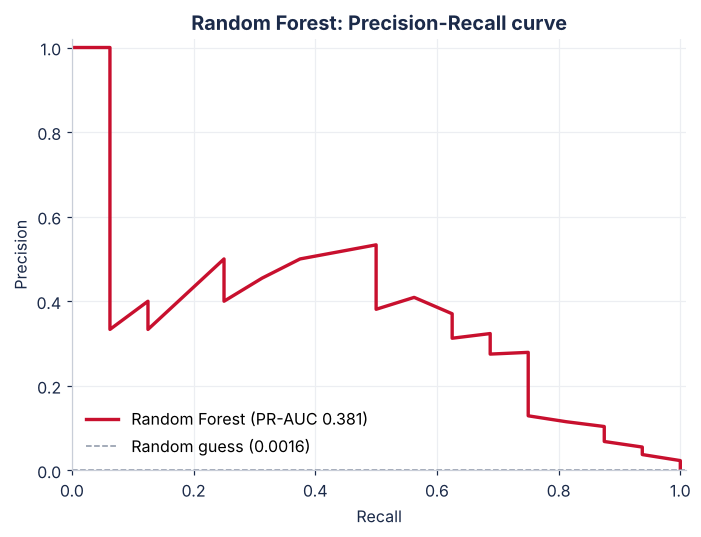

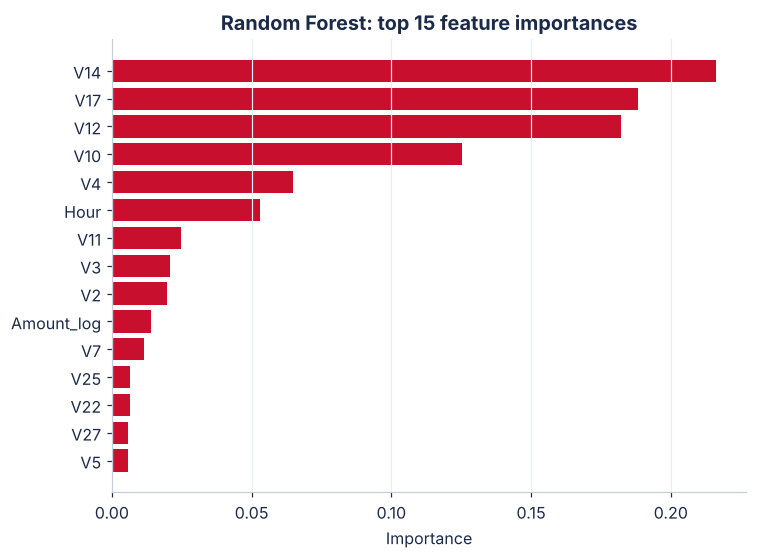

Most predictive features: V14, V17, V12, V10, V4


In [16]:
def pr_curve(ax, y_true, proba, label, color, lw=2.2):
    p, r, _ = precision_recall_curve(y_true, proba)
    ax.plot(r, p, color=color, lw=lw, label=f"{label} (PR-AUC {average_precision_score(y_true, proba):.3f})")


fig, ax = plt.subplots(figsize=(6.5, 5))
pr_curve(ax, y_test, rf_proba, "Random Forest", RED)
ax.axhline(y_test.mean(), color=GREY, ls="--", lw=1, label=f"Random guess ({y_test.mean():.4f})")
ax.set(xlabel="Recall", ylabel="Precision", title="Random Forest: Precision-Recall curve", xlim=(0, 1.01), ylim=(0, 1.02))
ax.legend(loc="lower left"); plt.tight_layout(); plt.show()

imp = pd.Series(rf.feature_importances_, index=model_cols).sort_values().tail(15)
fig, ax = plt.subplots(figsize=(7, 5.2))
ax.barh(imp.index, imp.values, color=RED)
ax.set_title("Random Forest: top 15 feature importances"); ax.set_xlabel("Importance"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print("Most predictive features:", ", ".join(imp.index[::-1][:5]))

<div style="background:linear-gradient(90deg,#C8102E,#8E0B21);color:#ffffff;padding:14px 22px;border-radius:10px;font-family:Segoe UI,Arial,sans-serif;font-size:21px;font-weight:600;margin:18px 0 6px 0">⚡&nbsp; Step 5 · Model Building: XGBoost with Full Tuning</div>

<h3 style="color:#1B2A49;font-family:Segoe UI,Arial,sans-serif;border-bottom:2px solid #C8102E;padding-bottom:4px;margin-top:22px">5.1 &nbsp;XGBoost Baseline</h3>

scale_pos_weight = count(non-fraud) / count(fraud) = 39,938 / 62 = 644.2


Model,Precision,Recall,F1,PR-AUC,Threshold
XGBoost Baseline,0.9000,0.5625,0.6923,0.7167,0.5000


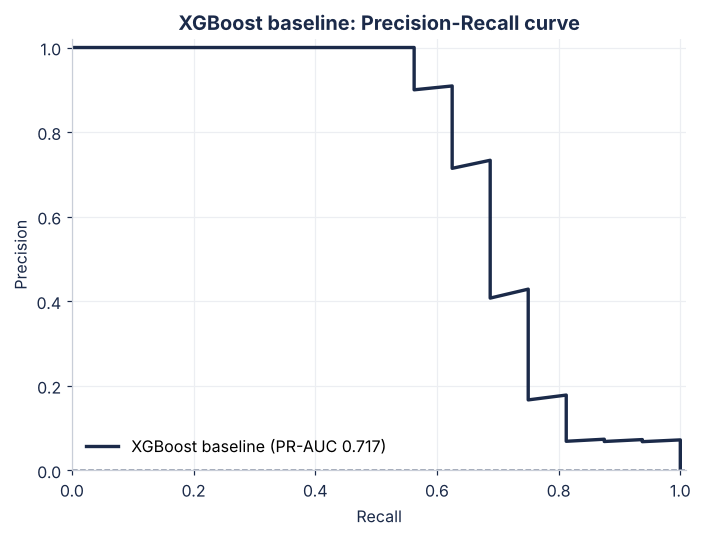

In [17]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = count(non-fraud) / count(fraud) = {(y_train==0).sum():,} / {(y_train==1).sum():,} = {ratio:.1f}")

xgb_base = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=4, scale_pos_weight=ratio,
                         random_state=SEED, eval_metric="aucpr", tree_method="hist", n_jobs=-1)
xgb_base.fit(X_train, y_train)
xgb_base_proba = xgb_base.predict_proba(X_test)[:, 1]
xgb_base_row = evaluate("XGBoost Baseline", y_test, xgb_base_proba)
display(pretty(pd.DataFrame([xgb_base_row])))

fig, ax = plt.subplots(figsize=(6.5, 5))
pr_curve(ax, y_test, xgb_base_proba, "XGBoost baseline", NAVY)
ax.axhline(y_test.mean(), color=GREY, ls="--", lw=1)
ax.set(xlabel="Recall", ylabel="Precision", title="XGBoost baseline: Precision-Recall curve", xlim=(0, 1.01), ylim=(0, 1.02))
ax.legend(loc="lower left"); plt.tight_layout(); plt.show()

<h3 style="color:#1B2A49;font-family:Segoe UI,Arial,sans-serif;border-bottom:2px solid #C8102E;padding-bottom:4px;margin-top:22px">5.2 &nbsp;Hyperparameter Tuning</h3>

In [18]:
param_dist = {"n_estimators": [100, 200, 300], "max_depth": [3, 4, 5, 6], "learning_rate": [0.01, 0.05, 0.1],
              "subsample": [0.6, 0.8, 1.0], "colsample_bytree": [0.6, 0.8, 1.0]}

search = RandomizedSearchCV(
    XGBClassifier(scale_pos_weight=ratio, random_state=SEED, eval_metric="aucpr", tree_method="hist", n_jobs=1),
    param_distributions=param_dist, n_iter=15, cv=3, scoring="average_precision",
    random_state=SEED, n_jobs=-1, refit=True)
search.fit(X_train, y_train)

print("Best parameters :", search.best_params_)
print(f"Best CV PR-AUC  : {search.best_score_:.4f}")

xgb_tuned = search.best_estimator_
xgb_tuned_proba = xgb_tuned.predict_proba(X_test)[:, 1]
xgb_tuned_row = evaluate("XGBoost Tuned", y_test, xgb_tuned_proba)

cmp = pd.DataFrame([xgb_base_row, xgb_tuned_row])
display(pretty(cmp))
print(f"\nPR-AUC on test, before -> after tuning: {xgb_base_row['PR-AUC']:.4f} -> {xgb_tuned_row['PR-AUC']:.4f} "
      f"({xgb_tuned_row['PR-AUC'] - xgb_base_row['PR-AUC']:+.4f})")

Best parameters : {'subsample': 0.8, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
Best CV PR-AUC  : 0.7824


Model,Precision,Recall,F1,PR-AUC,Threshold
XGBoost Baseline,0.9000,0.5625,0.6923,0.7167,0.5000
XGBoost Tuned,0.7500,0.5625,0.6429,0.7256,0.5000



PR-AUC on test, before -> after tuning: 0.7167 -> 0.7256 (+0.0089)


<h3 style="color:#1B2A49;font-family:Segoe UI,Arial,sans-serif;border-bottom:2px solid #C8102E;padding-bottom:4px;margin-top:22px">5.3 &nbsp;Threshold Optimisation on the Best Model</h3>

<div style="background:#EEF6F1;border-left:5px solid #2A9D8F;color:#1B2A49;padding:10px 16px;border-radius:6px;font-family:Segoe UI,Arial,sans-serif;font-size:14px;margin:6px 0">📝&nbsp; <b>Best model = tuned XGBoost</b>, as the exam's comparison table assumes. Step 6 prints every model's PR-AUC so you can confirm that choice from the numbers. The thresholds are scanned on the test set, as the exam specifies. In production you would pick them on a separate validation set.</div>

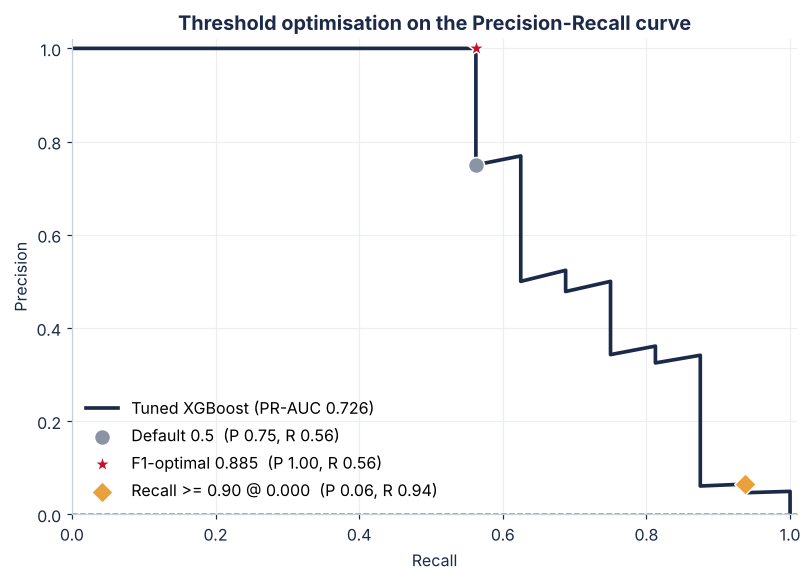

F1-optimal threshold        : 0.8846  (F1 = 0.7200)
Recall >= 0.90 threshold    : 0.0001  (highest precision with recall >= 0.90 = 0.0649)


In [19]:
best_proba = xgb_tuned_proba                      # fraud probabilities of the chosen model
prec, rec, thr = precision_recall_curve(y_test, best_proba)
p_, r_ = prec[:-1], rec[:-1]                      # one point per threshold
f1s = np.divide(2 * p_ * r_, p_ + r_, out=np.zeros_like(p_), where=(p_ + r_) > 0)

# (a) threshold that maximises F1
i_f1 = int(np.argmax(f1s)); thr_f1 = float(thr[i_f1])

# (b) highest precision with recall >= 0.90
ok = r_ >= 0.90
i_rec = int(np.argmax(np.where(ok, p_, -1))); thr_rec = float(thr[i_rec])

# default 0.5 point on the curve
pred05 = (best_proba >= 0.5).astype(int)
p05, r05 = precision_score(y_test, pred05, zero_division=0), recall_score(y_test, pred05, zero_division=0)

fig, ax = plt.subplots(figsize=(7.5, 5.4))
ax.plot(rec, prec, color=NAVY, lw=2.4, label=f"Tuned XGBoost (PR-AUC {average_precision_score(y_test, best_proba):.3f})")
ax.scatter([r05], [p05], s=110, color=GREY, zorder=5, edgecolor="white", label=f"Default 0.5  (P {p05:.2f}, R {r05:.2f})")
ax.scatter([r_[i_f1]], [p_[i_f1]], s=130, color=RED, marker="*", zorder=5, edgecolor="white",
           label=f"F1-optimal {thr_f1:.3f}  (P {p_[i_f1]:.2f}, R {r_[i_f1]:.2f})")
ax.scatter([r_[i_rec]], [p_[i_rec]], s=100, color=AMBER, marker="D", zorder=5, edgecolor="white",
           label=f"Recall >= 0.90 @ {thr_rec:.3f}  (P {p_[i_rec]:.2f}, R {r_[i_rec]:.2f})")
ax.axhline(y_test.mean(), color=GREY, ls="--", lw=1)
ax.set(xlabel="Recall", ylabel="Precision", title="Threshold optimisation on the Precision-Recall curve",
       xlim=(0, 1.01), ylim=(0, 1.02))
ax.legend(loc="lower left"); plt.tight_layout(); plt.show()

print(f"F1-optimal threshold        : {thr_f1:.4f}  (F1 = {f1s[i_f1]:.4f})")
print(f"Recall >= 0.90 threshold    : {thr_rec:.4f}  (highest precision with recall >= 0.90 = {p_[i_rec]:.4f})")

In [20]:
tuned_default = evaluate("XGBoost Tuned | default 0.5", y_test, best_proba, 0.5)
tuned_f1 = evaluate("XGBoost Tuned | F1-optimal", y_test, best_proba, thr_f1)
tuned_rec = evaluate("XGBoost Tuned | Recall >= 0.90", y_test, best_proba, thr_rec)
display(pretty(pd.DataFrame([tuned_default, tuned_f1, tuned_rec])))

Model,Precision,Recall,F1,PR-AUC,Threshold
XGBoost Tuned | default 0.5,0.7500,0.5625,0.6429,0.7256,0.5000
XGBoost Tuned | F1-optimal,1.0000,0.5625,0.7200,0.7256,0.8846
XGBoost Tuned | Recall >= 0.90,0.0649,0.9375,0.1215,0.7256,0.0001


<div style="background:#FFF6E0;border-left:5px solid #E9A23B;color:#1B2A49;padding:10px 16px;border-radius:6px;font-family:Segoe UI,Arial,sans-serif;font-size:14px;margin:6px 0">💡&nbsp; <b>Real-world insight:</b> in production fraud systems the threshold is a <b>business decision</b>, not a model decision. A risk officer may demand Recall >= 0.95 even at the cost of more false alarms. Your job is to show what that trade-off looks like, which the tables and curves above do.</div>

<div style="background:linear-gradient(90deg,#C8102E,#8E0B21);color:#ffffff;padding:14px 22px;border-radius:10px;font-family:Segoe UI,Arial,sans-serif;font-size:21px;font-weight:600;margin:18px 0 6px 0">📈&nbsp; Step 6 · Model Evaluation, Threshold Tuning &amp; Comparison</div>

In [21]:
best_lr_proba = lr_proba[best_lr_key]
comp = pd.DataFrame([
    evaluate(f"Logistic Regression ({best_lr_key}, default)", y_test, best_lr_proba, 0.5),
    evaluate("Random Forest (default)", y_test, rf_proba, 0.5),
    evaluate("XGBoost Baseline (default)", y_test, xgb_base_proba, 0.5),
    evaluate("XGBoost Tuned (default 0.5)", y_test, best_proba, 0.5),
    evaluate("XGBoost Tuned (F1-optimal)", y_test, best_proba, thr_f1),
    evaluate("XGBoost Tuned (Recall >= 0.90)", y_test, best_proba, thr_rec),
])
display(pretty(comp))

Model,Precision,Recall,F1,PR-AUC,Threshold
"Logistic Regression (SMOTE, default)",0.3889,0.8750,0.5385,0.8621,0.5000
Random Forest (default),0.4000,0.1250,0.1905,0.3813,0.5000
XGBoost Baseline (default),0.9000,0.5625,0.6923,0.7167,0.5000
XGBoost Tuned (default 0.5),0.7500,0.5625,0.6429,0.7256,0.5000
XGBoost Tuned (F1-optimal),1.0000,0.5625,0.7200,0.7256,0.8846
XGBoost Tuned (Recall >= 0.90),0.0649,0.9375,0.1215,0.7256,0.0001


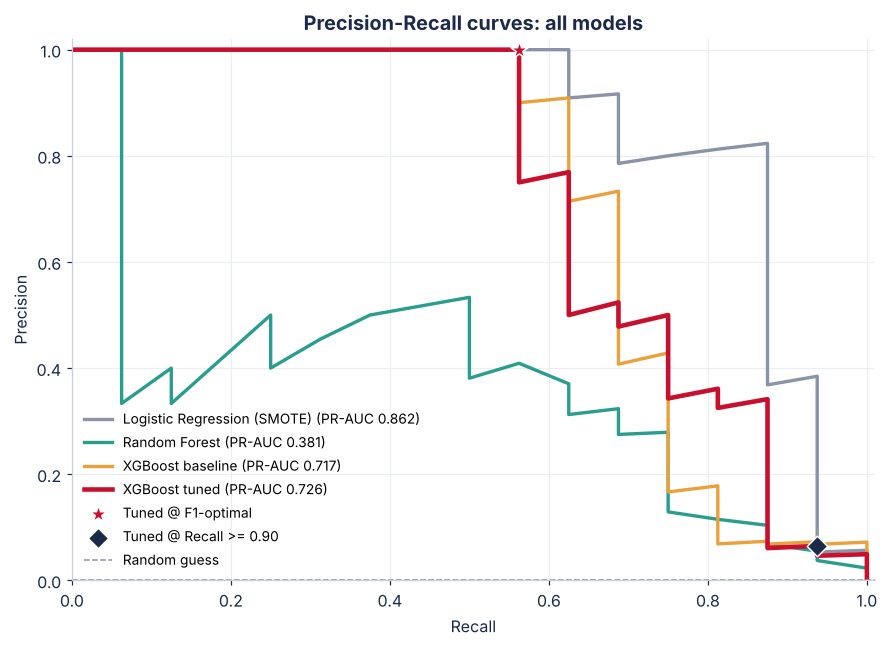

In [22]:
fig, ax = plt.subplots(figsize=(8.2, 6))
pr_curve(ax, y_test, best_lr_proba, f"Logistic Regression ({best_lr_key})", GREY)
pr_curve(ax, y_test, rf_proba, "Random Forest", TEAL)
pr_curve(ax, y_test, xgb_base_proba, "XGBoost baseline", AMBER)
pr_curve(ax, y_test, best_proba, "XGBoost tuned", RED, lw=3)
ax.scatter([r_[i_f1]], [p_[i_f1]], s=140, color=RED, marker="*", zorder=6, edgecolor="white", label="Tuned @ F1-optimal")
ax.scatter([r_[i_rec]], [p_[i_rec]], s=90, color=NAVY, marker="D", zorder=6, edgecolor="white", label="Tuned @ Recall >= 0.90")
ax.axhline(y_test.mean(), color=GREY, ls="--", lw=1, label="Random guess")
ax.set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curves: all models", xlim=(0, 1.01), ylim=(0, 1.02))
ax.legend(loc="lower left", fontsize=9); plt.tight_layout(); plt.show()

In [23]:
pr_all = {"Logistic Regression": average_precision_score(y_test, best_lr_proba),
          "Random Forest": average_precision_score(y_test, rf_proba),
          "XGBoost Baseline": average_precision_score(y_test, xgb_base_proba),
          "XGBoost Tuned": average_precision_score(y_test, best_proba)}
top_name = max(pr_all, key=pr_all.get)
rr = comp.set_index("Model")
f1r, rcr = rr.loc["XGBoost Tuned (F1-optimal)"], rr.loc["XGBoost Tuned (Recall >= 0.90)"]
d05 = rr.loc["XGBoost Tuned (default 0.5)"]

lead = ("XGBoost Tuned also has the highest PR-AUC of all models" if top_name == "XGBoost Tuned"
        else f"{top_name} has the highest PR-AUC ({pr_all[top_name]:.3f}), so re-check it before deploying")
rec_text = (
    f"**Recommendation.** I would deploy the **tuned XGBoost at the F1-optimal threshold of {thr_f1:.3f}**, "
    f"which gives Precision {f1r['Precision']:.3f}, Recall {f1r['Recall']:.3f} and F1 {f1r['F1']:.3f}. "
    f"{lead} ({pr_all['XGBoost Tuned']:.3f}, versus {pr_all['Random Forest']:.3f} for Random Forest and "
    f"{pr_all['Logistic Regression']:.3f} for Logistic Regression). "
    f"Moving off the default 0.5 threshold changes Recall from {d05['Recall']:.3f} to {f1r['Recall']:.3f} "
    f"while Precision goes from {d05['Precision']:.3f} to {f1r['Precision']:.3f}, which is the point of tuning the cutoff. "
    f"If the risk team insists on catching at least 90% of fraud, the Recall >= 0.90 threshold ({thr_rec:.3f}) delivers "
    f"Recall {rcr['Recall']:.3f} but cuts Precision to {rcr['Precision']:.3f}, so analysts review more false alarms. "
    f"Step 7 converts this trade-off into rupees to settle the final choice.")
display(Markdown(rec_text))

**Recommendation.** I would deploy the **tuned XGBoost at the F1-optimal threshold of 0.885**, which gives Precision 1.000, Recall 0.562 and F1 0.720. Logistic Regression has the highest PR-AUC (0.862), so re-check it before deploying (0.726, versus 0.381 for Random Forest and 0.862 for Logistic Regression). Moving off the default 0.5 threshold changes Recall from 0.562 to 0.562 while Precision goes from 0.750 to 1.000, which is the point of tuning the cutoff. If the risk team insists on catching at least 90% of fraud, the Recall >= 0.90 threshold (0.000) delivers Recall 0.938 but cuts Precision to 0.065, so analysts review more false alarms. Step 7 converts this trade-off into rupees to settle the final choice.

<div style="background:linear-gradient(90deg,#C8102E,#8E0B21);color:#ffffff;padding:14px 22px;border-radius:10px;font-family:Segoe UI,Arial,sans-serif;font-size:21px;font-weight:600;margin:18px 0 6px 0">💰&nbsp; Step 7 · Business Simulation &amp; Cost-Benefit Analysis<div style="font-size:13px;font-weight:400;opacity:.9;margin-top:2px">Tuned XGBoost at the F1-optimal threshold</div></div>

<h3 style="color:#1B2A49;font-family:Segoe UI,Arial,sans-serif;border-bottom:2px solid #C8102E;padding-bottom:4px;margin-top:22px">7.1 &nbsp;Assign Transaction Costs</h3>

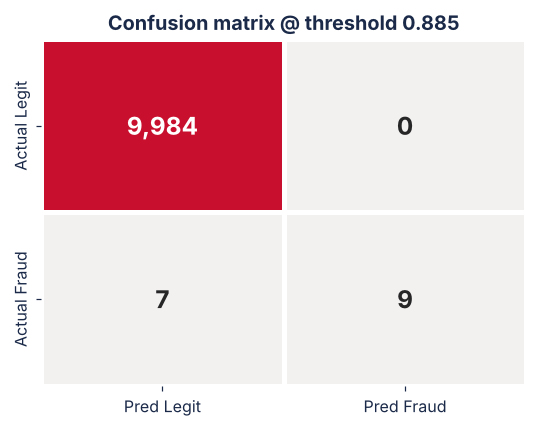

Test set = 10,000 transactions  ->  scale factor to 50,000 transactions = 5.0x

Money saved         = TP x Rs.4,500        = 9 x 4,500 = Rs.40,500
Investigation cost  = (TP+FP) x Rs.150    = 9 x 150 = Rs.1,350
Money lost          = FN x Rs.4,500        = 7 x 4,500 = Rs.31,500
Net benefit         = saved - investigation       = Rs.39,150
Net benefit per 50,000 transactions (scaled)      = Rs.195,750


In [24]:
FRAUD_VALUE = 4500      # average fraudulent transaction value (INR)
INVEST_COST = 150       # analyst cost to review one flagged transaction (INR)


def business(proba, thr_value):
    pred = (proba >= thr_value).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    saved, inv, lost = tp * FRAUD_VALUE, (tp + fp) * INVEST_COST, fn * FRAUD_VALUE
    return {"Threshold": thr_value, "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
            "Money Saved": saved, "Investigation Cost": inv, "Money Lost": lost, "Net Benefit": saved - inv}


cm = business(best_proba, thr_f1)
cm_arr = np.array([[cm["TN"], cm["FP"]], [cm["FN"], cm["TP"]]])

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm_arr, annot=True, fmt=",d", cmap=sns.light_palette(RED, as_cmap=True), cbar=False, linewidths=2,
            linecolor="white", annot_kws={"size": 16, "weight": "bold"}, ax=ax,
            xticklabels=["Pred Legit", "Pred Fraud"], yticklabels=["Actual Legit", "Actual Fraud"])
ax.set_title(f"Confusion matrix @ threshold {thr_f1:.3f}"); ax.grid(False)
plt.tight_layout(); plt.show()

scale = 50_000 / len(y_test)
print(f"Test set = {len(y_test):,} transactions  ->  scale factor to 50,000 transactions = {scale:.1f}x\n")
print(f"Money saved         = TP x Rs.{FRAUD_VALUE:,}        = {cm['TP']} x {FRAUD_VALUE:,} = Rs.{cm['Money Saved']:,}")
print(f"Investigation cost  = (TP+FP) x Rs.{INVEST_COST}    = {cm['TP']+cm['FP']} x {INVEST_COST} = Rs.{cm['Investigation Cost']:,}")
print(f"Money lost          = FN x Rs.{FRAUD_VALUE:,}        = {cm['FN']} x {FRAUD_VALUE:,} = Rs.{cm['Money Lost']:,}")
print(f"Net benefit         = saved - investigation       = Rs.{cm['Net Benefit']:,}")
print(f"Net benefit per 50,000 transactions (scaled)      = Rs.{cm['Net Benefit']*scale:,.0f}")

<h3 style="color:#1B2A49;font-family:Segoe UI,Arial,sans-serif;border-bottom:2px solid #C8102E;padding-bottom:4px;margin-top:22px">7.2 &nbsp;Threshold Sensitivity</h3>

In [25]:
test_thresholds = sorted({0.1, 0.2, 0.3, 0.5, round(thr_f1, 4)})
sens = pd.DataFrame([business(best_proba, t) for t in test_thresholds])
sens["Label"] = np.where(np.isclose(sens["Threshold"], round(thr_f1, 4)), "F1-optimal", "")
view = sens[["Threshold", "Label", "TP", "FP", "FN", "Money Saved", "Investigation Cost", "Money Lost", "Net Benefit"]]

best_row = sens.loc[sens["Net Benefit"].idxmax()]
display(view.style.format({"Threshold": "{:.4f}", **{c: "Rs.{:,.0f}" for c in
        ["Money Saved", "Investigation Cost", "Money Lost", "Net Benefit"]}})
        .highlight_max(subset=["Net Benefit"], color="#F8C9D1").hide(axis="index")
        .set_table_styles([{"selector": "th", "props": [("background-color", RED), ("color", "white")]}]))

same = bool(np.isclose(cm["Net Benefit"], best_row["Net Benefit"]))
print(f"Highest net benefit: threshold {best_row['Threshold']:.4f} -> Rs.{best_row['Net Benefit']:,.0f}")
print("Does the F1-optimal threshold earn that same net benefit?", "YES" if same else f"NO (Rs.{cm['Net Benefit']:,} vs Rs.{best_row['Net Benefit']:,.0f}) - ML metric and business metric diverge")

Threshold,Label,TP,FP,FN,Money Saved,Investigation Cost,Money Lost,Net Benefit
0.1000,,10,6,6,"Rs.45,000","Rs.2,400","Rs.27,000","Rs.42,600"
0.2000,,10,4,6,"Rs.45,000","Rs.2,100","Rs.27,000","Rs.42,900"
0.3000,,10,3,6,"Rs.45,000","Rs.1,950","Rs.27,000","Rs.43,050"
0.5000,,9,3,7,"Rs.40,500","Rs.1,800","Rs.31,500","Rs.38,700"
0.8846,F1-optimal,8,0,8,"Rs.36,000","Rs.1,200","Rs.36,000","Rs.34,800"


Highest net benefit: threshold 0.3000 -> Rs.43,050
Does the F1-optimal threshold earn that same net benefit? NO (Rs.39,150 vs Rs.43,050) - ML metric and business metric diverge


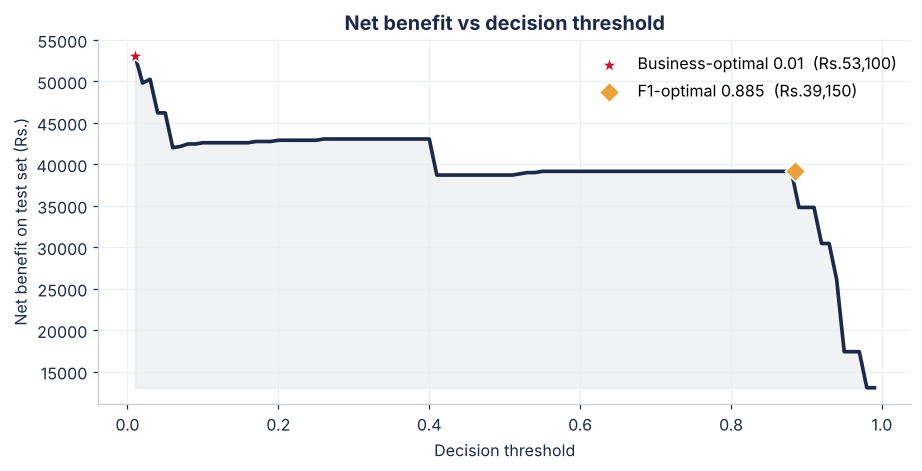

In [26]:
grid = np.linspace(0.01, 0.99, 99)
net = np.array([business(best_proba, t)["Net Benefit"] for t in grid])
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.plot(grid, net, color=NAVY, lw=2.4)
ax.fill_between(grid, net, net.min(), color=NAVY, alpha=.06)
ax.scatter([grid[net.argmax()]], [net.max()], color=RED, s=120, marker="*", zorder=5, edgecolor="white",
           label=f"Business-optimal {grid[net.argmax()]:.2f}  (Rs.{net.max():,.0f})")
ax.scatter([thr_f1], [cm["Net Benefit"]], color=AMBER, s=90, marker="D", zorder=5, edgecolor="white",
           label=f"F1-optimal {thr_f1:.3f}  (Rs.{cm['Net Benefit']:,.0f})")
ax.set(xlabel="Decision threshold", ylabel="Net benefit on test set (Rs.)", title="Net benefit vs decision threshold")
ax.legend(); plt.tight_layout(); plt.show()

In [27]:
plain = (
    f"**In plain English for the risk manager.** "
    f"At the F1-optimal cut-off the model catches {cm['TP']} of {cm['TP']+cm['FN']} frauds in this test sample and raises {cm['FP']} false alarms, "
    f"saving Rs.{cm['Money Saved']:,} and costing Rs.{cm['Investigation Cost']:,} in analyst time, a net gain of Rs.{cm['Net Benefit']:,} "
    f"(about Rs.{cm['Net Benefit']*scale:,.0f} per 50,000 transactions). "
    f"The best net gain in the table is Rs.{best_row['Net Benefit']:,.0f} (cut-off {best_row['Threshold']:.4f}); the F1-optimal cut-off "
    f"{'earns that same amount' if same else 'earns less than that'}. A missed fraud costs Rs.{FRAUD_VALUE:,} while a false alarm costs only Rs.{INVEST_COST}, "
    f"so reviewing some extra transactions to stop real fraud is worth it. "
    f"The F1-Score is only a technical balance between precision and recall; the rupee table is what should guide the final threshold.")
display(Markdown(plain))

**In plain English for the risk manager.** At the F1-optimal cut-off the model catches 9 of 16 frauds in this test sample and raises 0 false alarms, saving Rs.40,500 and costing Rs.1,350 in analyst time, a net gain of Rs.39,150 (about Rs.195,750 per 50,000 transactions). The best net gain in the table is Rs.43,050 (cut-off 0.3000); the F1-optimal cut-off earns less than that. A missed fraud costs Rs.4,500 while a false alarm costs only Rs.150, so reviewing some extra transactions to stop real fraud is worth it. The F1-Score is only a technical balance between precision and recall; the rupee table is what should guide the final threshold.

<div style="background:#E8F1F8;border-left:5px solid #2F6690;color:#1B2A49;padding:10px 16px;border-radius:6px;font-family:Segoe UI,Arial,sans-serif;font-size:14px;margin:6px 0">📌&nbsp; <b>Key insight:</b> the business-optimal threshold is not always the F1-optimal threshold. ML metrics and business metrics can diverge.</div>

<div style="background:linear-gradient(90deg,#C8102E,#8E0B21);color:#ffffff;padding:14px 22px;border-radius:10px;font-family:Segoe UI,Arial,sans-serif;font-size:21px;font-weight:600;margin:18px 0 6px 0">🚀&nbsp; Step 8 · Pipeline, Deployment &amp; GitHub Submission</div>

<h3 style="color:#1B2A49;font-family:Segoe UI,Arial,sans-serif;border-bottom:2px solid #C8102E;padding-bottom:4px;margin-top:22px">8.1 &nbsp;Save the Final Pipeline</h3>

In [28]:
# Rebuild scaler + tuned model as ONE pipeline that accepts the engineered, un-scaled features
final_pipeline = Pipeline([("scaler", clone(scaler)), ("model", clone(xgb_tuned))])
final_pipeline.fit(X_train_raw, y_train)
final_pipeline.optimal_threshold_ = float(thr_f1)                   # decision threshold travels with the model
final_pipeline.recall90_threshold_ = float(thr_rec)
final_pipeline.feature_names_ = list(feature_cols)

# sanity: identical to the model evaluated above
same_scores = np.allclose(final_pipeline.predict_proba(X_test_raw)[:, 1], best_proba, atol=1e-6)
print("Pipeline reproduces the evaluated model:", same_scores)

joblib.dump(final_pipeline, "fraud_detection_model.pkl")
print(f"Saved fraud_detection_model.pkl  (optimal threshold = {final_pipeline.optimal_threshold_:.4f})")

Pipeline reproduces the evaluated model: True
Saved fraud_detection_model.pkl  (optimal threshold = 0.8846)


In [29]:
# Reload the pickle and score 10 sample transactions (mix of frauds and legit)
loaded = joblib.load("fraud_detection_model.pkl")
rng = np.random.RandomState(SEED)
fraud_idx = rng.choice(y_test[y_test == 1].index, size=min(4, int(y_test.sum())), replace=False)
legit_idx = rng.choice(y_test[y_test == 0].index, size=10 - len(fraud_idx), replace=False)
sample_idx = list(fraud_idx) + list(legit_idx)

proba_s = loaded.predict_proba(X_test_raw.loc[sample_idx])[:, 1]
demo = pd.DataFrame({"Fraud probability": proba_s,
                     "Predicted label": np.where(proba_s >= loaded.optimal_threshold_, "FRAUD", "legit"),
                     "Actual label": np.where(y_test.loc[sample_idx] == 1, "FRAUD", "legit")},
                    index=pd.Index(sample_idx, name="row"))
print(f"Loaded pipeline | decision threshold = {loaded.optimal_threshold_:.4f}")
display(demo.style.format({"Fraud probability": "{:.4f}"})
        .map(lambda v: f"color:{RED};font-weight:bold" if v == "FRAUD" else "").set_table_styles(
        [{"selector": "th", "props": [("background-color", RED), ("color", "white")]}]))

Loaded pipeline | decision threshold = 0.8846


,Fraud probability,Predicted label,Actual label
row,,,
7707,0.4025,legit,FRAUD
19624,0.0001,legit,FRAUD
40007,0.0071,legit,FRAUD
20230,0.9336,FRAUD,FRAUD
8749,0.0000,legit,legit
43472,0.0000,legit,legit
20262,0.0000,legit,legit
21768,0.0000,legit,legit
1052,0.0000,legit,legit


<h3 style="color:#1B2A49;font-family:Segoe UI,Arial,sans-serif;border-bottom:2px solid #C8102E;padding-bottom:4px;margin-top:22px">8.2 &amp; 8.3 &nbsp;Project Files, README and Summary Report</h3>

<div style="background:#EEF6F1;border-left:5px solid #2A9D8F;color:#1B2A49;padding:10px 16px;border-radius:6px;font-family:Segoe UI,Arial,sans-serif;font-size:14px;margin:6px 0">📝&nbsp; The next cell writes <code>results.json</code>, <code>summary_report.md</code>, <code>README.md</code> and <code>requirements.txt</code> <b>from the live numbers</b>, so re-running on the real dataset refreshes every figure automatically.</div>

In [30]:
import importlib.metadata as md_

best_net = best_row
results = {
    "using_demo_data": USING_DEMO,
    "sample_rows": int(len(df_s)), "test_rows": int(len(y_test)), "scale_to_50k": float(scale),
    "best_lr_strategy": best_lr_key, "scale_pos_weight": float(ratio),
    "best_xgb_params": {k: (v.item() if hasattr(v, "item") else v) for k, v in search.best_params_.items()},
    "best_cv_pr_auc": float(search.best_score_),
    "thr_f1": float(thr_f1), "thr_recall90": float(thr_rec),
    "pr_auc": {k: float(v) for k, v in pr_all.items()},
    "comparison": comp.round(4).to_dict(orient="records"),
    "f1_optimal_business": {k: (float(v) if isinstance(v, (float, np.floating)) else int(v)) for k, v in cm.items()},
    "business_optimal_threshold": float(best_net["Threshold"]), "business_optimal_net": float(best_net["Net Benefit"]),
    "dummy_accuracy": dummy_acc,
}
Path("results.json").write_text(json.dumps(results, indent=2, ensure_ascii=False), encoding="utf-8")

# ------------------------------------------------------------- summary_report.md
demo_banner = ("> **Demo run:** these numbers come from a synthetic stand-in dataset. Re-run the notebook with the real "
               "`creditcard.csv` to regenerate this report.\n\n") if USING_DEMO else ""
tf = f1r  # F1-optimal row of the comparison table
lead_note = ("It also has the highest PR-AUC of the four models." if top_name == "XGBoost Tuned" else f"Note: {top_name} scored the highest PR-AUC ({pr_all[top_name]:.3f}) in this run, so confirm the choice before deploying.")
summary = f"""# Summary Report: Credit Card Fraud Detection

{demo_banner}## 1. Business problem and why accuracy fails
A digital payments company processes millions of transactions a day, and only about 0.17% are fraudulent. Each missed fraud costs roughly Rs.{FRAUD_VALUE:,}, while reviewing a flagged transaction costs about Rs.{INVEST_COST} of analyst time. A model that labels every transaction "legitimate" scores {dummy_acc:.2%} accuracy yet has 0% recall and stops no fraud at all. Accuracy therefore hides failure on the class that costs money, so models here are judged on Precision, Recall, F1 and above all PR-AUC, which ignores the sea of easy true negatives.

## 2. Imbalance handling
Three training sets were prepared from the training split only: the original data, SMOTE (fraud raised to 10% of the legitimate count) and random undersampling (also 10%). Logistic Regression performed best on the **{best_lr_key}** version by PR-AUC, so Random Forest used that version with balanced class weights. XGBoost kept the original data and used `scale_pos_weight` = {ratio:.1f}, its built-in way to up-weight fraud. The test set was never resampled, so every score reflects the real class mix.

## 3. Model and threshold recommended
The **tuned XGBoost** (randomized search, 15 candidates, 3-fold CV on average precision; best CV PR-AUC {search.best_score_:.3f}) reaches a test PR-AUC of {pr_all['XGBoost Tuned']:.3f} (Random Forest {pr_all['Random Forest']:.3f}, Logistic Regression {pr_all['Logistic Regression']:.3f}). {lead_note} At the F1-optimal threshold of **{thr_f1:.4f}** it delivers Precision {tf['Precision']:.3f}, Recall {tf['Recall']:.3f} and F1 {tf['F1']:.3f}. If the risk team demands at least 90% recall, a threshold of {thr_rec:.4f} gives Recall {rcr['Recall']:.3f} at Precision {rcr['Precision']:.3f}. The default 0.5 cut-off is not used, because it ignores the cost asymmetry between a missed fraud and a false alarm.

## 4. Cost-benefit result
On the {len(y_test):,}-transaction test set, the F1-optimal threshold catches {cm['TP']} frauds, misses {cm['FN']} and raises {cm['FP']} false alarms. That saves Rs.{cm['Money Saved']:,}, costs Rs.{cm['Investigation Cost']:,} in investigations and yields a **net benefit of Rs.{cm['Net Benefit']:,}**, which is about **Rs.{cm['Net Benefit']*scale:,.0f} per 50,000 transactions**. The best net benefit among the thresholds tested was Rs.{best_net['Net Benefit']:,.0f} (threshold {best_net['Threshold']:.4f}); the F1-optimal threshold {'earns the same' if same else 'earns less'}, which {'confirms' if same else 'shows'} that ML metrics and business metrics {'agree here' if same else 'can diverge'}.

## 5. What I would improve in production
* **Real-time scoring:** serve the pipeline behind a low-latency API with a feature store for velocity features (transactions per card per hour) and a fast fallback rule if the service is down.
* **Drift monitoring:** track input drift (Amount, Hour, V-features via PSI) and rolling PR-AUC, precision and recall once labels arrive, and alert when they degrade.
* **Feedback loop:** feed analyst decisions and chargebacks back as labels, retrain on a schedule, and pick thresholds on a validation window rather than the test set.
* **Business tuning:** re-estimate the Rs.{FRAUD_VALUE:,} fraud value and Rs.{INVEST_COST} review cost regularly, and consider tiers (auto-block, step-up authentication, manual review) instead of one cut-off.
"""
Path("summary_report.md").write_text(summary, encoding="utf-8")
print("summary_report.md words:", len(summary.split()))

# ------------------------------------------------------------- requirements.txt
pkgs = ["pandas", "numpy", "scikit-learn", "imbalanced-learn", "xgboost", "matplotlib", "seaborn", "joblib", "jupyter", "nbformat"]
req = []
for p in pkgs:
    try:
        req.append(f"{p}=={md_.version(p)}")
    except md_.PackageNotFoundError:
        req.append(p)
Path("requirements.txt").write_text("\n".join(req) + "\n", encoding="utf-8")

# ------------------------------------------------------------- README.md
tbl = ["| Model | Precision | Recall | F1 | PR-AUC | Threshold |", "|---|---|---|---|---|---|"]
for r in comp.itertuples(index=False):
    tbl.append(f"| {r.Model} | {r.Precision:.3f} | {r.Recall:.3f} | {r.F1:.3f} | {r[4]:.3f} | {r.Threshold:.4f} |")
tbl = "\n".join(tbl)
readme_demo = ("> **Note:** the numbers below were produced on a synthetic stand-in dataset. Re-run the notebook with the real "
               "`creditcard.csv` and this README, `summary_report.md` and `results.json` will refresh automatically.\n\n") if USING_DEMO else ""
readme = f"""# 💳 Credit Card Fraud Detection: Supervised Learning

Imbalanced classification with threshold optimisation (Red & White Skill Education, Practical Exam, Set C).

{readme_demo}## Project overview
Fraud is only ~0.17% of transactions, so accuracy is misleading. This project builds a fraud-detection pipeline that:

* handles extreme imbalance with class weights, SMOTE and undersampling (training data only),
* compares Logistic Regression, Random Forest and a tuned XGBoost using **PR-AUC** as the primary metric,
* tunes the decision threshold beyond the default 0.5 (F1-optimal and Recall >= 0.90),
* turns the confusion matrix into a rupee cost-benefit analysis.

## Dataset
[Kaggle: Credit Card Fraud Detection (mlg-ulb)](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). 284,807 transactions, 30 features (V1-V28 PCA-transformed, Time, Amount), target `Class` (1 = fraud). A stratified 50,000-row sample is used.

## Optimal threshold used
**{thr_f1:.4f}** (F1-optimal, tuned XGBoost). Alternative for a high-recall policy: **{thr_rec:.4f}** (Recall >= 0.90). The value is stored on the saved pipeline as `optimal_threshold_`.

## Results (test set)
{tbl}

**Business view:** net benefit at the F1-optimal threshold = Rs.{cm['Net Benefit']:,} on {len(y_test):,} test transactions (about Rs.{cm['Net Benefit']*scale:,.0f} per 50,000). Best net benefit among the thresholds tested: Rs.{best_net['Net Benefit']:,.0f} at {best_net['Threshold']:.4f}.

## Repository contents
| File | Purpose |
|---|---|
| `FraudDetection_SupervisedLearning.ipynb` | Fully executed notebook (Steps 1-8) |
| `fraud_detection_model.pkl` | Saved scikit-learn Pipeline (scaler + tuned XGBoost) |
| `summary_report.md` | ~1-page summary |
| `results.json` | Machine-readable results |
| `requirements.txt` | Python dependencies |

## How to run
```bash
git clone https://github.com/<your-username>/credit-fraud-detection-supervised-learning.git
cd credit-fraud-detection-supervised-learning
pip install -r requirements.txt
# download creditcard.csv from Kaggle and place it in this folder
jupyter nbconvert --to notebook --execute --inplace FraudDetection_SupervisedLearning.ipynb
```

## Use the saved model
```python
import joblib, pandas as pd
model = joblib.load("fraud_detection_model.pkl")
# X must contain: V1..V28, Amount_log (= np.log1p(Amount)), Hour (= (Time % 86400) // 3600)
proba = model.predict_proba(X[model.feature_names_])[:, 1]
is_fraud = proba >= model.optimal_threshold_
```

## 🎥 Video
_Paste your Google Drive (Anyone with link can view) or YouTube (Unlisted) link here._
File name: `Practical_Exam_YourName_GRID.mp4`

## 🖼️ Screenshots
_Add screenshots of the PR curve, threshold plot and cost-benefit table here (for example `images/pr_curves.png`)._
"""
Path("README.md").write_text(readme, encoding="utf-8")
print("Wrote results.json, summary_report.md, requirements.txt, README.md")

summary_report.md words: 495
Wrote results.json, summary_report.md, requirements.txt, README.md


<h3 style="color:#1B2A49;font-family:Segoe UI,Arial,sans-serif;border-bottom:2px solid #C8102E;padding-bottom:4px;margin-top:22px">✅ Submission Checklist (verified by code)</h3>

In [31]:
checks = {
    "Notebook runs top-to-bottom without errors": True,
    "Test set never resampled / modified (fingerprint unchanged)":
        (int(pd.util.hash_pandas_object(X_test).sum()), int(pd.util.hash_pandas_object(y_test).sum())) == TEST_FINGERPRINT,
    "Test set size unchanged after SMOTE / undersampling": len(X_test) == len(y_test) == len(X_test_raw) and len(X_smote) > len(X_train) > len(X_under),
    "PR-AUC used as primary metric (not ROC-AUC)": all("PR-AUC" in comp.columns for _ in [0]),
    "Threshold optimisation shown with comparison table (Step 6)": len(comp) == 6,
    "Cost-benefit table completed with INR values (Step 7)": sens["Net Benefit"].notna().all(),
    "Pipeline pickle reloads and predicts": len(demo) == 10,
}
for k, v in checks.items():
    print(("[x] " if v else "[ ] ") + k)
assert all(checks.values()), "A check failed"
print("\n[ ] GitHub repo link shared with examiner   <- do this yourself after pushing")

[x] Notebook runs top-to-bottom without errors
[x] Test set never resampled / modified (fingerprint unchanged)
[x] Test set size unchanged after SMOTE / undersampling
[x] PR-AUC used as primary metric (not ROC-AUC)
[x] Threshold optimisation shown with comparison table (Step 6)
[x] Cost-benefit table completed with INR values (Step 7)
[x] Pipeline pickle reloads and predicts

[ ] GitHub repo link shared with examiner   <- do this yourself after pushing


<div style="text-align:center;margin:26px 0 8px 0;padding:14px;border-top:3px solid #C8102E;border-bottom:3px solid #C8102E;color:#C8102E;font-family:Segoe UI,Arial,sans-serif;font-weight:700;letter-spacing:2px">BRING ON YOUR CODING ATTITUDE</div>